# 2.1 The agent loop

We build a PydanticAI agent that reads an ad brief and makes the first keyframe image.
Then we open up the loop the framework runs for us:

- who decides the next step,
- what goes over the wire on each turn,
- where the run stops.

You're done when:

- the agent produces one image from one brief,
- `events.jsonl` shows every model request and tool call in order,
- you can say whether your Homework 2 brief needs an agent, a workflow or a hybrid.

Run the cells top to bottom. Every section follows the same rhythm: see the result, read one mechanism, run it, change one thing.

In [ ]:
%load_ext autoreload
%autoreload 2

import sys
from pathlib import Path

MODULE = "02-multi-agent-media-workflows"
candidates = [Path.cwd(), Path.cwd() / "code", Path.cwd() / MODULE / "code"]
CODE = next(p for p in candidates if (p / "tools.py").exists())
sys.path.insert(0, str(CODE))
ASSETS = CODE.parent / "assets"

## Choose a mode

`MODE` decides which LLM the agent talks to. The image tool is a placeholder in both modes: it draws the prompt on a flat PNG.

| `MODE` | LLM | Image tool | Network | Cost |
| --- | --- | --- | --- | --- |
| `"fake"` | You: a Python function plays the LLM | Placeholder PNG | None | Free |
| `"fake-gpu"` | A real LLM on Token Factory | Placeholder PNG | Token Factory only | A few cents of tokens [measure] |

`"fake-gpu"` means the GPU is fake, not the LLM.
Cells that need the real LLM check `MODE` and skip themselves in `"fake"`.

To switch, edit the cell below and run it again. No kernel restart needed.

In [ ]:
from fake import block_real_models

MODE = "fake"  # "fake" or "fake-gpu"

# In "fake" mode, any request to a real LLM fails, so a fake run can't spend tokens.
# The switch is process-wide, so this line also turns it back on for "fake-gpu".
block_real_models(MODE == "fake")
print(f"MODE = {MODE!r}: real LLM requests {'blocked' if MODE == 'fake' else 'allowed'}")

## Start with the finished result

This is where the module ends up: a trace of one full run.
The agent plans, makes a keyframe, a judge rejects it, the agent makes a second one, the judge passes it, and the agent makes the video.

Every model request, tool call and check is one line of `events.jsonl`. The cell loads a saved trace from `assets/`, so it needs no credits.

The trace in `assets/worked-trace/` is hand-written. Its numbers show how the totals add up; they aren't measured.

In [ ]:
from tracing import read_events, summarize

saved = ASSETS / "reference-run" / "events.jsonl"  # a measured run, once the course ships one
if not saved.exists():
    saved = ASSETS / "worked-trace" / "events.jsonl"  # hand-written, illustrative numbers
print("Trace:", saved.relative_to(ASSETS.parent), "\n")

events = read_events(saved)
for e in events:
    print(f"{e.kind:14} {e.name:15} {e.workload or '':9} {e.verdict or '':6} ${e.cost_usd:.4f}")

totals = summarize(events)
print("\nSteps (model requests + tool calls):", totals["steps"])
print("Cost by step:", totals["cost_by_step"])
print(f"Cost of this video: ${totals['marginal_cost_usd']:.4f}")

## How the agent loop works

One `agent.run()` is a loop:

1. The agent sends the LLM a model request: the instructions, the schema of every tool, and the whole conversation so far.
2. The LLM answers with either a tool call or text.
3. A tool call: the agent runs the function and appends the call and its result to the conversation. Back to step 1.
4. Text: the loop ends, and `agent.run()` returns it.

The LLM never runs anything. It only picks the next step. Running the tool, keeping the history and deciding when to stop is plain code in the framework.

`call_id` links a tool call to its result, in the conversation and in `events.jsonl`.

![The agent loop: your code calls agent.run; the agent sends a model request with instructions, tool schemas and the full history; the LLM answers with a tool call or text; on a tool call the agent checks usage limits, runs the tool and appends the call and its return to the history; on text the loop ends and the result goes back to your code](attachment:diagram-agent-loop.png)
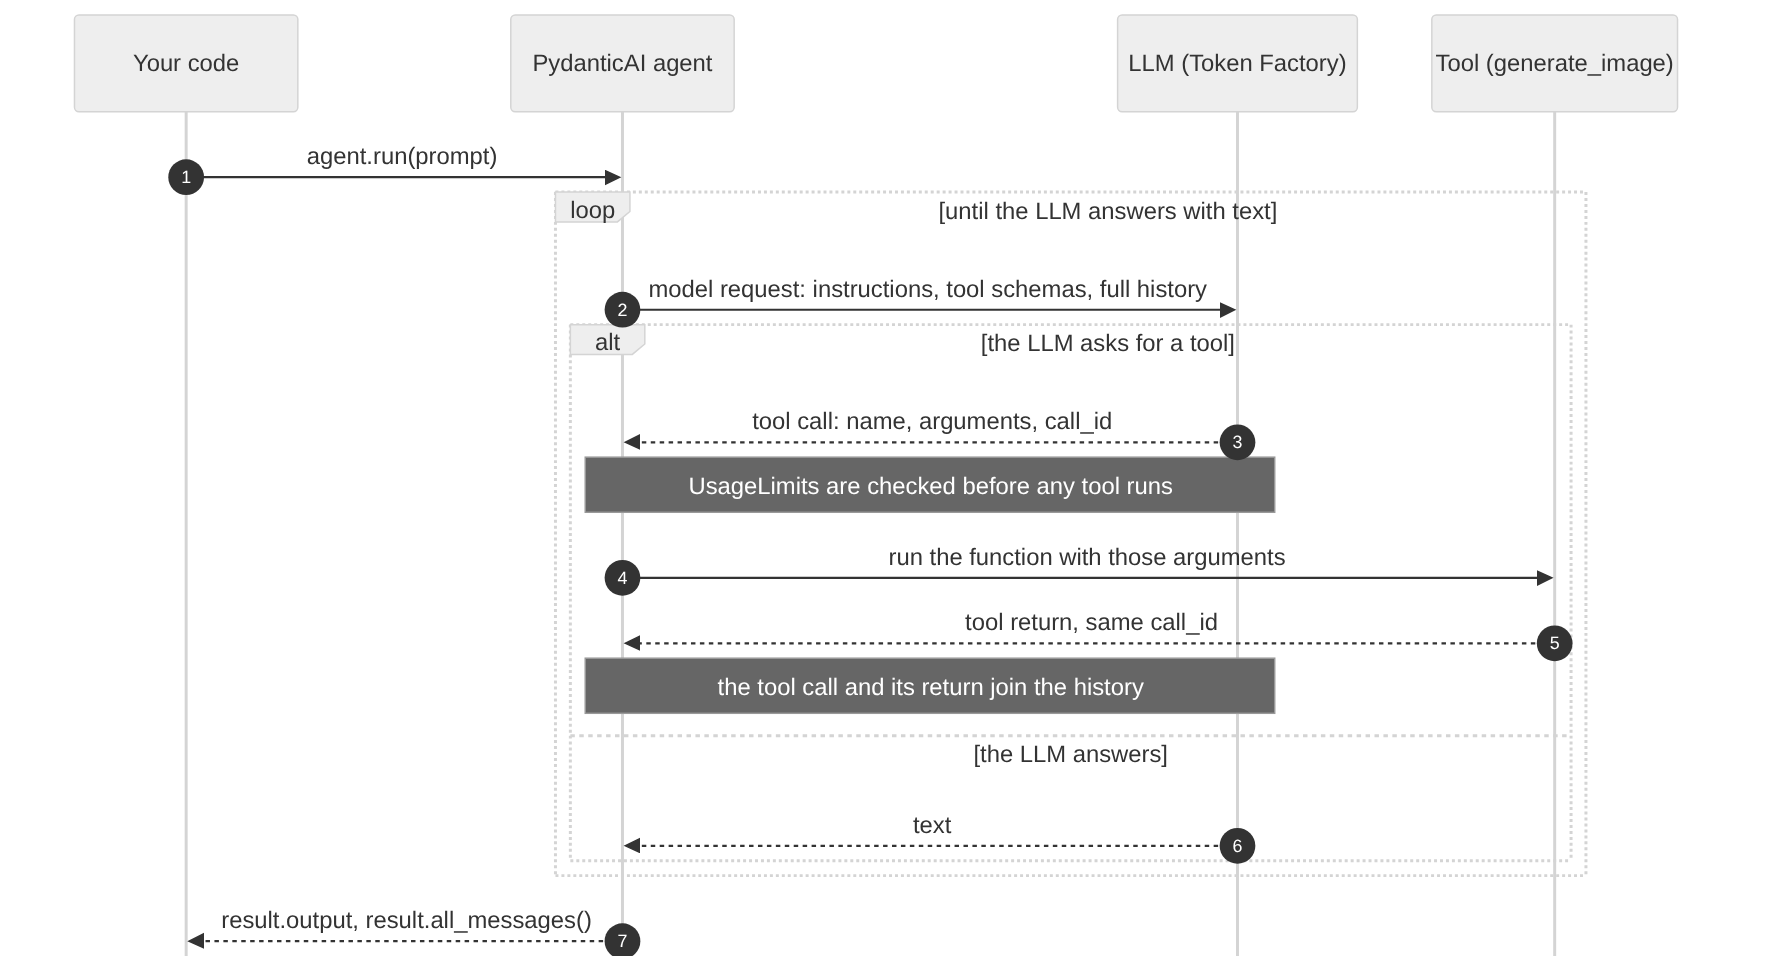

## Agent, workflow or hybrid

Three ways to wire the same steps:

- **Workflow:** code decides the next step. `plan() → keyframe() → video()`, always in that order.
- **Agent:** the LLM decides the next step. It gets tools and picks which one to call, with which arguments, and when to stop.
- **Hybrid:** code fixes the stages, and the LLM decides inside a stage.

The trace above is a hybrid: plan → keyframe → judge → video.

- The stages are fixed in code. A video costs far more than a keyframe, and the model must never skip the judge.
- Inside the keyframe stage, the model picks the tool call and its arguments.

In the common vocabulary, the fixed stages are *prompt chaining*, and judge → regenerate is *evaluator-optimizer*.

**Exercise:** in the trace above, mark each line as decided by code or by the model.
Find the tool call the model chose. That's the part that makes the example agentic.

## The brief

The input for the whole module is one `Brief`. Homework 2 uses the same fields.

In [ ]:
from models import Brief

brief = Brief.from_yaml(ASSETS / "brief.yaml")
brief

## A minimal agent

### The tool

A tool is a typed Python function.

- PydanticAI reads its signature and docstring and sends them to the model as a JSON schema.
- `ctx.deps` carries what the tool needs at run time. Here it's the tracer that writes `events.jsonl`.
- `ctx.tool_call_id` is the `call_id` the model gave this call.

The image is a placeholder: the prompt drawn on a flat PNG. Here we care about the loop, not the pixels.

In [ ]:
from pydantic_ai import Agent, RunContext

from fake import placeholder_png
from tracing import Tracer, new_run_id


async def generate_image(ctx: RunContext[Tracer], prompt: str, seed: int = 7) -> str:
    """Generate one keyframe image for the ad and return its file path."""
    path = ctx.deps.folder / f"keyframe-seed{seed}.png"
    path.write_bytes(placeholder_png(prompt, 832, 480, seed))
    ctx.deps.emit("tool_call", "generate_image", call_id=ctx.tool_call_id, asset_ref=str(path))
    return str(path)


INSTRUCTIONS = "You make one keyframe image for a video ad brief. Call generate_image once."


def make_agent(model) -> Agent:
    """The same agent for every model in this notebook: one tool, one instruction."""
    return Agent(model, deps_type=Tracer, tools=[generate_image], instructions=INSTRUCTIONS)

### Be the LLM

Before any real model, we play the LLM ourselves.
[`FunctionModel`](https://pydantic.dev/docs/ai/api/models/function/) calls a Python function with two things:

- `messages`: the conversation so far, as PydanticAI message objects.
- `info`: what the agent offers, including `info.function_tools`.

The function returns the next message. Ours asks for one tool call, then reports the result.

It also prints what it receives on each turn. Each message is a `request` (sent to the model) or a `response` (from the model). Each holds parts:

| Part | Who adds it |
| --- | --- |
| `user-prompt` | Your code, in `agent.run(prompt)` |
| `tool-call` | The model, in its response |
| `tool-return` | The agent, after it runs the tool |
| `text` | The model, when it answers |

**Exercise:** before you run the cell, predict how many messages the function sees on each turn.

In [ ]:
from pydantic_ai.messages import ModelResponse, TextPart, ToolCallPart
from pydantic_ai.models.function import AgentInfo, FunctionModel


def describe(messages: list) -> str:
    """One line per conversation: each message's kind and its parts."""
    return " | ".join(f"{m.kind}[{', '.join(p.part_kind for p in m.parts)}]" for m in messages)


def be_the_llm(messages: list, info: AgentInfo) -> ModelResponse:
    """A hand-written model: call generate_image, then report the result."""
    print(f"Model sees {len(messages)} message(s): {describe(messages)}")
    print(f"  tools on offer: {[t.name for t in info.function_tools]}")
    last = messages[-1].parts[-1]
    if last.part_kind == "tool-return":
        return ModelResponse(parts=[TextPart(f"Keyframe ready: {last.content}")])
    return ModelResponse(parts=[ToolCallPart("generate_image", {"prompt": brief.shot, "seed": 7})])


agent = make_agent(FunctionModel(be_the_llm))
prompt = f"Brief: {brief.model_dump_json()}"
tracer = Tracer(new_run_id())
result = await agent.run(prompt, deps=tracer)
print("\nOutput:", result.output)

What happened:

- **Turn 1, 1 message.** `request[user-prompt]`: your prompt. The function answers with a tool call.
- **Turn 2, 3 messages.** The prompt, then `response[tool-call]` (the model's own call), then `request[tool-return]` (the agent ran the tool and sent the result back). The function answers with text, so the loop ends.

The model has no memory between turns. The history *is* its memory, and the agent resends all of it every turn.
The instructions travel with every request too, but outside the message parts.

**Exercise:** change `seed` in the tool call and run the cell again. Find the difference in the output file name.

### Swap in the real LLM

Two steps:

1. Call Token Factory directly, without PydanticAI. You see what a model actually returns.
2. Give PydanticAI the same model. The agent runs unchanged.

**Step 1: one raw API call.** Token Factory speaks the OpenAI API, so the `openai` client works with its `base_url`.
The model ID is pinned in `code/models.py` as `LLM`.

The tool schema below is written by hand. In the agent, PydanticAI builds it from `generate_image`'s signature and docstring.

The first run asks for your Token Factory API key and saves it to `code/.env`.

In [ ]:
if MODE == "fake-gpu":
    from openai import AsyncOpenAI

    from models import LLM
    from tools import settings

    api_key = settings("NEBIUS_API_KEY", secret=("NEBIUS_API_KEY",))["NEBIUS_API_KEY"]
    client = AsyncOpenAI(base_url=LLM.base_url, api_key=api_key)

    image_tool = {
        "type": "function",
        "function": {
            "name": "generate_image",
            "description": "Generate one keyframe image for the ad and return its file path.",
            "parameters": {
                "type": "object",
                "properties": {"prompt": {"type": "string"}, "seed": {"type": "integer"}},
                "required": ["prompt"],
            },
        },
    }
    response = await client.chat.completions.create(
        model=LLM.model,
        messages=[
            {"role": "system", "content": INSTRUCTIONS},
            {"role": "user", "content": prompt},
        ],
        tools=[image_tool],
    )
    message = response.choices[0].message
    print("Model:", LLM.model)
    print("Text:", message.content)
    for tool_call in message.tool_calls or []:
        print("Tool call:", tool_call.id, tool_call.function.name, tool_call.function.arguments)
    print("Tokens in/out:", response.usage.prompt_tokens, response.usage.completion_tokens)
else:
    print('Skipped: set MODE = "fake-gpu" to call the real LLM.')

The model only *asked* for a tool. Nothing ran.

To finish the job yourself, you would:

1. run `generate_image` with those arguments,
2. append the model's message and a `tool` message with the same `id` and the result,
3. call the API again, and repeat until the model answers with text.

That's the loop from the diagram. PydanticAI runs it for you.

**Step 2: the same model through PydanticAI.** `OpenAIChatModel` with an `OpenAIProvider` pointed at Token Factory. Only the model changes; `make_agent` stays the same.

In [ ]:
if MODE == "fake-gpu":
    from pydantic_ai.models.openai import OpenAIChatModel
    from pydantic_ai.providers.openai import OpenAIProvider

    tf_model = OpenAIChatModel(
        LLM.model, provider=OpenAIProvider(base_url=LLM.base_url, api_key=api_key)
    )
    agent = make_agent(tf_model)
    result = await agent.run(prompt, deps=tracer)
    print(result.output)
else:
    print('Skipped: set MODE = "fake-gpu" to call the real LLM.')

The printout has the same shape as with `be_the_llm`. Now the LLM chooses the prompt and the seed.

The shared `code/tools.py` wraps these lines as `token_factory_model()`, and the scripts in `code/` use it. Same model, same key from `code/.env`.

### What goes over the wire

The conversation of the last run, one line per message. With `"fake"` it's the `be_the_llm` run; with `"fake-gpu"` the real one.

In [ ]:
for message in result.all_messages():
    print(f"{message.kind:9}", [part.part_kind for part in message.parts])

With `"fake-gpu"`, the next cell records the raw HTTP requests the agent sends and prints the second one.

Two things to notice:

- `tools` is sent on **every** turn: the schema of `generate_image`, built from the signature and docstring.
- `messages` holds the **whole** history: the brief, the model's tool call, the tool result.

Each turn resends everything before it, so input tokens grow with every step. In our run: request 1 [measure] input tokens, request 2 [measure].

In [ ]:
if MODE == "fake-gpu":
    import json

    import httpx

    sent = []

    async def keep(request: httpx.Request) -> None:
        sent.append(json.loads(request.content))

    spy_client = AsyncOpenAI(
        base_url=LLM.base_url,
        api_key=api_key,
        http_client=httpx.AsyncClient(event_hooks={"request": [keep]}),
    )
    spy = make_agent(OpenAIChatModel(LLM.model, provider=OpenAIProvider(openai_client=spy_client)))
    await spy.run(prompt, deps=tracer)
    second = sent[1]
    print(json.dumps(second["tools"], indent=1)[:1200])
    for m in second["messages"]:
        print(m["role"], str(m.get("content"))[:70], "+ tool_calls" if m.get("tool_calls") else "")
else:
    print('Skipped: set MODE = "fake-gpu" to see the real request.')

## Step through a run with agent.iter()

`agent.run()` returns the answer and hides how many requests it made.
`agent.iter()` yields each node of the run as it happens:

- `UserPromptNode`: your prompt enters the run.
- `ModelRequestNode`: one request to the LLM. Costs tokens.
- `CallToolsNode`: runs the tools the model asked for. A tool may cost GPU time.
- `End`: the model answered with text.

Count both kinds of node, and you know what a run costs before you look at a bill.

In [ ]:
async with agent.iter(prompt, deps=tracer) as run:
    async for node in run:
        print(type(node).__name__)
print(run.result.output)

## Stop conditions

A model that never stops asking for images would call a paid tool forever.
Limits live in code, not in the prompt.

[`UsageLimits`](https://pydantic.dev/docs/ai/core-concepts/agent/) stops a run that goes over a limit with `UsageLimitExceeded`:

| Limit | Counts | Misses |
| --- | --- | --- |
| `request_limit` | Model requests | GPU spend |
| `tool_calls_limit` | Tool calls. Checked before the tools run, so none of a parallel batch runs if it would go over | GPU spend |
| `output_tokens_limit` and the other token limits | LLM tokens | GPU spend |
| `cost_limit` | LLM cost the framework estimates, best effort | GPU spend. [verify: whether it's computed for Token Factory models] |

Every row misses the same thing. A GPU tool call adds nothing to the framework's usage, yet the image or video it starts can cost more than all the tokens of the run. GPU spend needs a budget guard of its own.

The cell below runs a scripted model that asks for a new image every turn, with `tool_calls_limit=3`.

In [ ]:
from pydantic_ai import UsageLimitExceeded, UsageLimits


def never_stops(messages: list, info: AgentInfo) -> ModelResponse:
    """Ask for another image every turn, with a new seed."""
    return ModelResponse(
        parts=[ToolCallPart("generate_image", {"prompt": brief.shot, "seed": len(messages)})]
    )


before = len(tracer.events())
try:
    await make_agent(FunctionModel(never_stops)).run(
        prompt, deps=tracer, usage_limits=UsageLimits(tool_calls_limit=3)
    )
except UsageLimitExceeded as exc:
    print("Stopped:", exc)
ran = sum(e.kind == "tool_call" for e in tracer.events()[before:])
print("generate_image ran", ran, "times")

**Exercise:** set `tool_calls_limit=5`. Predict how many times `generate_image` runs before the run stops, then run the cell.

## Where state lives

The conversation lives in memory and dies with the process.
Save it to the run folder as `messages.json`, and a new process can continue it with `message_history=`.

`messages.json` holds only the conversation. A GPU request still running when the process dies isn't in it.

In [ ]:
from tracing import load_messages, save_messages

path = save_messages(tracer.folder, result.all_messages())
print(path, path.stat().st_size, "bytes")

restored = load_messages(tracer.folder)
again = await agent.run("Make one more with seed 8.", message_history=restored, deps=tracer)
print(again.output)

## Picking an LLM for tool calling

The course default is pinned in `code/models.py` as `LLM`.
We picked it by measuring tool calling on Token Factory, not from a model card:

| Model | Valid tool calls | Tokens per run | Latency |
| --- | --- | --- | --- |
| [measure: author bench, 10 runs each on 3 candidates] | | | |

To try another model, change `LLM` in `models.py`, then run the mode cell and the "Swap in the real LLM" cells again.
Token Factory's [function calling docs](https://docs.tokenfactory.nebius.com/ai-models-inference/function-calling) describe the API. Check the model list for which models support tools.

A model ID that Token Factory no longer serves fails with `ModelNotFoundError` (404) on the first request.

## Trace events

Printed nodes vanish when the notebook closes. The trace stays.

`run_traced()` in `tracing.py` drives `agent.iter()`:

- it writes one `model_request` event per model response,
- the tool writes its own `tool_call` event,
- both carry the tool call ID, so every tool call links to the request that asked for it.

Steps = model requests + tool calls.
`check()` from `check_trace.py` checks the events against the field contract.

In [ ]:
from check_trace import check
from tracing import run_traced

tracer = Tracer(new_run_id())
await run_traced(agent, prompt, tracer=tracer, deps=tracer)
for e in tracer.events():
    print(
        f"{e.kind:14} {e.name:16} call_id={e.call_id} parent={(e.parent_id or '-')[:8]} tokens_in={e.tokens_in}"
    )
print("Contract problems:", check(tracer.events()))
print(summarize(tracer.events()))
print("Run folder:", tracer.folder)

The same check from a terminal, on any saved run:

```bash
cd 02-multi-agent-media-workflows/code
uv run python check_trace.py runs/02-multi-agent-media-workflows/<run_id>/events.jsonl
```

Homework 2 asks for the same events.

**Exercise:** mark each line of your trace as decided by code or by the model, as you did with the finished run. Then answer for your Homework 2 brief: agent, workflow or hybrid, and why?

## Notes

- `run_traced()` also saves `messages.json` after every model response, so a crash loses at most the step in flight.
- Notebook cells call `await agent.run(...)`. Jupyter runs top-level `await`. `run_sync` inside a notebook needs `nest_asyncio` ([troubleshooting](https://pydantic.dev/docs/ai/overview/troubleshooting/)).
- After you edit a file in `code/`, `%autoreload` picks the change up on the next cell run.